# Çok Modlu Ürün Kategori Sınıflandırma — 1. Veri Hazırlama ve Metin Modeli


Bu not defteri, diğer iki notebookun kullandığı hazir_veri.csv ve split.csv dosyalarını Drive'daki onproje klasörüne kaydeder.

## 1. Kurulum

In [63]:
import sys, numpy, pandas, sklearn, tensorflow, matplotlib, PIL, kagglehub
print("python", sys.version.split()[0])
for ad, m in [("numpy", numpy), ("pandas", pandas), ("scikit-learn", sklearn),
              ("tensorflow", tensorflow), ("matplotlib", matplotlib),
              ("pillow", PIL), ("kagglehub", kagglehub)]:
    print(f"{ad}=={m.__version__}")   # requirements.txt için sürümleri öğrendim


python 3.13.16
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
tensorflow==2.21.0
matplotlib==3.10.0
pillow==11.3.0
kagglehub==1.0.2


In [64]:
# google Drive bağlantısı (çıktılar oturum kapansa da kaybolmasın diye Drive'a kaydediliyor)
from google.colab import drive
drive.mount("/content/drive")

import os
import re
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub

CIKTI = "/content/drive/MyDrive/onproje"   # bütün çıktıların kaydedileceği klasör
os.makedirs(CIKTI, exist_ok=True)           # klasör yoksa oluştur
TOHUM = 42                                  # tekrar üretilebilirlik için sabit tohum

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Verinin indirilmesi

In [65]:
veri_yolu = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")

Using Colab cache for faster access to the 'fashion-product-images-small' dataset.


In [66]:
!ls {veri_yolu}


images	myntradataset  styles.csv


In [67]:
!ls {veri_yolu}/images | wc -l   # görsel sayısı

44441


CSV'de 44.446 kayıt, `images` klasöründe 44.441 görsel var. Aradaki 5 kayıtlık fark aşağıda id bazında kontrol edilecek.

## 3. Veri hazırlama

### 3.1 Hatalı satırlar ve eksik veri incelemesi
`pd.read_csv` 6044. satırda "Expected 10 fields, saw 11" hatası verdi. Satıra bakınca ürün adında
tırnak içine alınmamış bir virgül olduğu görülüyor. Bu satırları silmek yerine onarıyoruz.

In [68]:
!sed -n '6044p' {veri_yolu}/styles.csv


44065,Men,Personal Care,Fragrance,Perfume and Body Mist,Blue,Spring,2017,Casual,Boss Men Perfume, After Shave Balm and Shower Gel Set


In [69]:
import csv
import pandas as pd

satirlar = []   # onarılmış satırlar burada toplanacak
onarilan = 0

# pd.read_csv bazı satırlarda hata verdi. Bu yüzden dosyayı csv.reader ile satır satır okudum
with open(f"{veri_yolu}/styles.csv", encoding="utf-8") as f:
    okuyucu = csv.reader(f)
    baslik = next(okuyucu)

    for satir in okuyucu:
        # ürün adında tırnaksız virgül varsa satır bölünür
        if len(satir) > 10:
            # ilk 9 sütun doğru ve geri kalan parçalar ürün adına ait, virgülle yeniden birleştiriyoruz
            satir = satir[:9] + [",".join(satir[9:])]
            onarilan += 1

        satirlar.append(satir)

# onarılmış satırlardan DataFrame oluşturtum
df = pd.DataFrame(satirlar, columns=baslik)

print("Toplam kayıt:", len(df))
print("Onarılan satır:", onarilan)


Toplam kayıt: 44446
Onarılan satır: 22


In [70]:
df.loc[df["id"] == "44065", "productDisplayName"]

,productDisplayName
6042,"Boss Men Perfume, After Shave Balm and Shower ..."


In [71]:
df.loc[df["id"] == "44065", "productDisplayName"].iloc[0]

'Boss Men Perfume, After Shave Balm and Shower Gel Set'

In [72]:
df["productDisplayName"].isna().sum() #nan olarak boş değer yok


np.int64(0)

In [73]:
(df["productDisplayName"] == "").sum() # '' gibi boş değerler yok

np.int64(0)

In [74]:
df["productDisplayName"].str.strip().eq("").sum() # '  ' gibi boş değerler yok .yani boş ürün adı yok

np.int64(0)

In [75]:
df["id"].duplicated().sum() # tekrar eden id yok mu var mı?

np.int64(0)

Boş ad görünmüyor, ancak çok kısa adlara bakınca 7 kaydın adında düz metin olarak "NA" yazdığı görülüyor.

In [76]:
kisa = df[df["productDisplayName"].str.len() < 3]


In [77]:
print(kisa)

          id gender masterCategory subCategory            articleType  \
3677   42878  Women    Accessories        Bags               Clutches   
14302  30991  Women  Personal Care   Fragrance  Perfume and Body Mist   
17652  45687    Men  Personal Care   Fragrance  Perfume and Body Mist   
22102  42863  Women    Accessories        Bags               Clutches   
23497  45698  Women  Personal Care   Fragrance  Perfume and Body Mist   
37549  30992    Men  Personal Care   Fragrance  Perfume and Body Mist   
40697  43119    Men  Personal Care   Fragrance  Perfume and Body Mist   

      baseColour  season  year   usage productDisplayName  
3677      Maroon  Summer  2012  Casual                 NA  
14302         NA  Spring  2017      NA                 NA  
17652         NA  Spring  2017      NA                 NA  
22102      Brown  Summer  2012  Casual                 NA  
23497         NA  Spring  2017      NA                 NA  
37549         NA  Spring  2017      NA                 

In [78]:
# replace tam eşleşme mi yapıyor mu diye deneme yaptım
deneme = pd.Series(["NA", "NAVY Blue Shirt", "Puma Shoes"])
print(deneme.replace("NA", np.nan))


0                NaN
1    NAVY Blue Shirt
2         Puma Shoes
dtype: object


In [79]:
df["productDisplayName"] = df["productDisplayName"].replace("NA", np.nan)


In [80]:
print("NaN ürün adı:", df["productDisplayName"].isna().sum())  # "NA" metni gerçek bir ad değil olmadığı için tam eşleşme ile NaN'a çevrildi
print("Toplam kayıt:", len(df))


NaN ürün adı: 7
Toplam kayıt: 44446


Görseli olmayan kayıtlar id bazında kontrol ediliyor.

In [81]:
print(os.path.exists(f"{veri_yolu}/images/15970.jpg"))


True


In [82]:
gorseller = []

for i in df["id"]:
    yol = f"{veri_yolu}/images/{i}.jpg"
    var_mi = os.path.exists(yol)
    gorseller.append(var_mi)

df["gorsel_var"] = gorseller

In [83]:
(~df["gorsel_var"]).sum() # görseli olmayanların sayısı

np.int64(5)

In [84]:
df[(~df["gorsel_var"])][["id", "articleType", "productDisplayName"]]


,id,articleType,productDisplayName
6697,39403,Shirts,U.S. Polo Assn. Men Black Tailored Fit Casual ...
16207,39410,Shirts,U.S. Polo Assn. Men Cream-Coloured Tailored Fi...
32324,39401,Jeans,U.S. Polo Assn. Denim Co. Men Blue Slim Straig...
36399,39425,Tshirts,U.S. Polo Assn. Men Red Polo T-Shirt
40022,12347,Suits,Fastrack Men Red Manhattan Regular Fit Solid F...


Yasaklı sütunlar neden kullanılmıyor?  
yasaklı olan bir parametre ile somut olarak örnekledim

In [85]:
df[df["subCategory"] == "Watches"]["articleType"].value_counts() # tahmin etmeye çalıştığımız cevabı zaten içeriyor


,count
articleType,
Watches,2542


In [86]:
#her alt kategoride kaç farklı sınıf var? 1 olanlarda alt kategori cevabı doğrudan veriyor


df.groupby("subCategory")["articleType"].nunique().sort_values()


,articleType
subCategory,
Beauty Accessories,1
Gloves,1
Eyewear,1
Flip Flops,1
Hair,1
Perfumes,1
Mufflers,1
Home Furnishing,1
Nails,1


### 3.2 Veri hazırlama



İncelemelerde bulunan bütün adımlar tek hücrede toplandı.
Tek kelimelik adlar incelenirken bulunan iki geçersiz ad da
(`RTV_LoadTest`, `productDisplayName`) listeye eklendi.

In [87]:
import os
import csv
import numpy as np
import pandas as pd

# satırlarda 9. parçadan sonrasını birleştirip ürün adı yaptım
satirlar = []
onarilan = 0
with open(f"{veri_yolu}/styles.csv", encoding="utf-8") as f:
    okuyucu = csv.reader(f)
    baslik = next(okuyucu)
    for satir in okuyucu:
        if len(satir) > 10:
            satir = satir[:9] + [",".join(satir[9:])]
            onarilan += 1
        satirlar.append(satir)

df = pd.DataFrame(satirlar, columns=baslik)
print("Başlangıç:", len(df), "| Onarılan satır:", onarilan)


# "NA": boş bırakılmış ad olrak 7 kayıt buldum
# "RTV_LoadTest": test kaydı; görseli spor ayakkabı ama Sandals etiketli (id 28319)
# "productDisplayName": ad yerine sütun başlığı yazılmış (id 24078)
gecersiz_adlar = ["NA", "RTV_LoadTest", "productDisplayName"]
df["productDisplayName"] = df["productDisplayName"].replace(gecersiz_adlar, np.nan)
print("Adı geçersiz kayıt:", df["productDisplayName"].isna().sum())


# Her kaydın görseli var mı?
gorseller = []
for i in df["id"]:
    yol = f"{veri_yolu}/images/{i}.jpg"
    gorseller.append(os.path.exists(yol))
df["gorsel_var"] = gorseller
print("Görseli olmayan kayıt:", (~df["gorsel_var"]).sum())

#  Temizlik
df = df[df["productDisplayName"].notna()]
print("Adı geçersiz olanlar çıkarıldıktan sonra:", len(df))

df = df[df["gorsel_var"]]
print("Görseli olmayanlar çıkarıldıktan sonra:", len(df))

# temizlik yaptıktan sonra en sık kullanılan 20 sınıfı seçtim.
top20 = df["articleType"].value_counts().head(20).index
df = df[df["articleType"].isin(top20)]
print("En sık 20 sınıf seçildikten sonra:", len(df))

# yalnızca model girdileri ve hedef kaldı
df = df[["id", "productDisplayName", "articleType"]].reset_index(drop=True)
print("Son hali:", df.shape)


Başlangıç: 44446 | Onarılan satır: 22
Adı geçersiz kayıt: 9
Görseli olmayan kayıt: 5
Adı geçersiz olanlar çıkarıldıktan sonra: 44437
Görseli olmayanlar çıkarıldıktan sonra: 44432
En sık 20 sınıf seçildikten sonra: 33142
Son hali: (33142, 3)


## 4. Keşifsel veri analizi

### 4.1 Sınıf dağılımı

In [88]:
sinif_sayilari = df["articleType"].value_counts()
print(sinif_sayilari)


articleType
Tshirts                  7069
Shirts                   3215
Casual Shoes             2846
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1322
Sunglasses               1073
Wallets                   936
Flip Flops                916
Sandals                   896
Briefs                    849
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     609
Jeans                     608
Name: count, dtype: int64


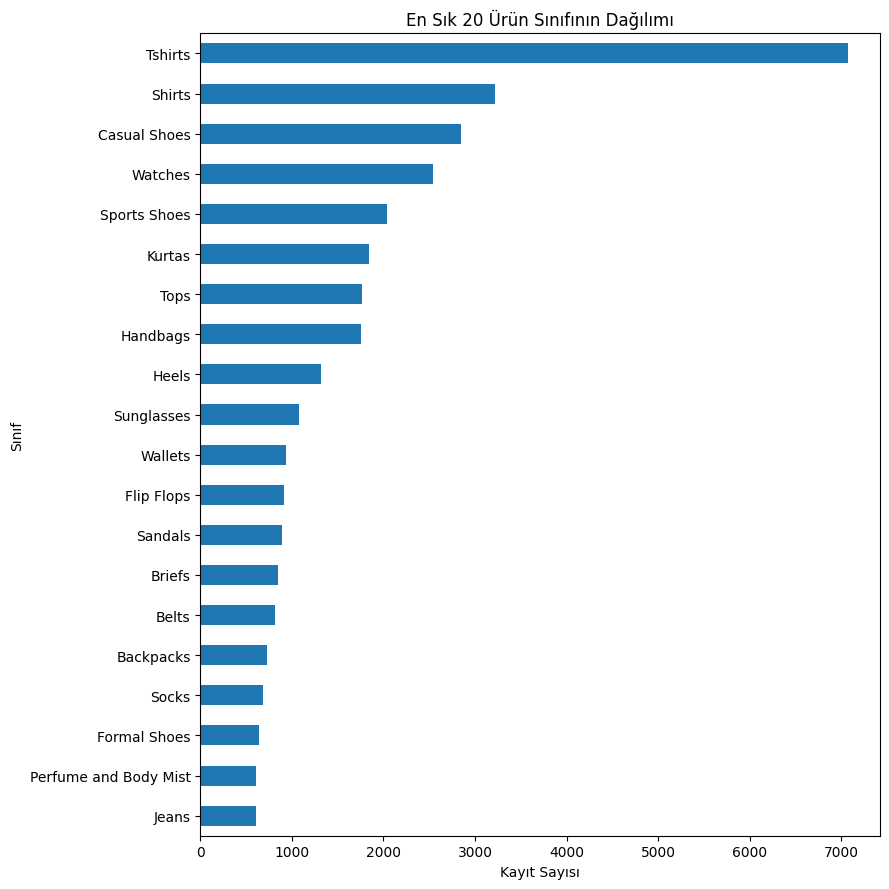

In [89]:
sinif_sayilari.plot(kind="barh", figsize=(9, 9))
plt.title("En Sık 20 Ürün Sınıfının Dağılımı")
plt.xlabel("Kayıt Sayısı")
plt.ylabel("Sınıf")
plt.gca().invert_yaxis() # en kalabalık sınıf en üstte
plt.tight_layout() # uzun sınıf adları kesilmesin
plt.savefig(f"{CIKTI}/sinif_dagilimi.png", dpi=150)
plt.show()


In [90]:
sinif_sayilari.max() / sinif_sayilari.min()



11.626644736842104

En büyük sınıf (Tshirts) en küçük sınıftan (Jeans) yaklaşık 11,6 kat büyük. Bu dengesizlik nedeniyle birincil ölçüt olarak makro-F1 kullanılıyor.

### 4.2 Örnek görseller

(60, 80)


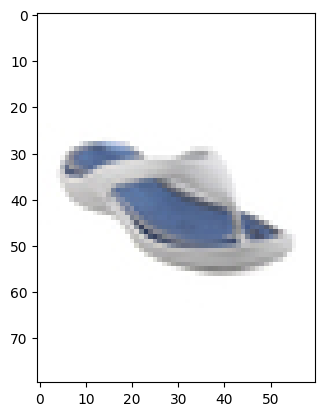

In [91]:
from PIL import Image

ornek_id = df["id"].iloc[67]
gorsel = Image.open(f"{veri_yolu}/images/{ornek_id}.jpg")
print(gorsel.size)
plt.imshow(gorsel)
plt.show()


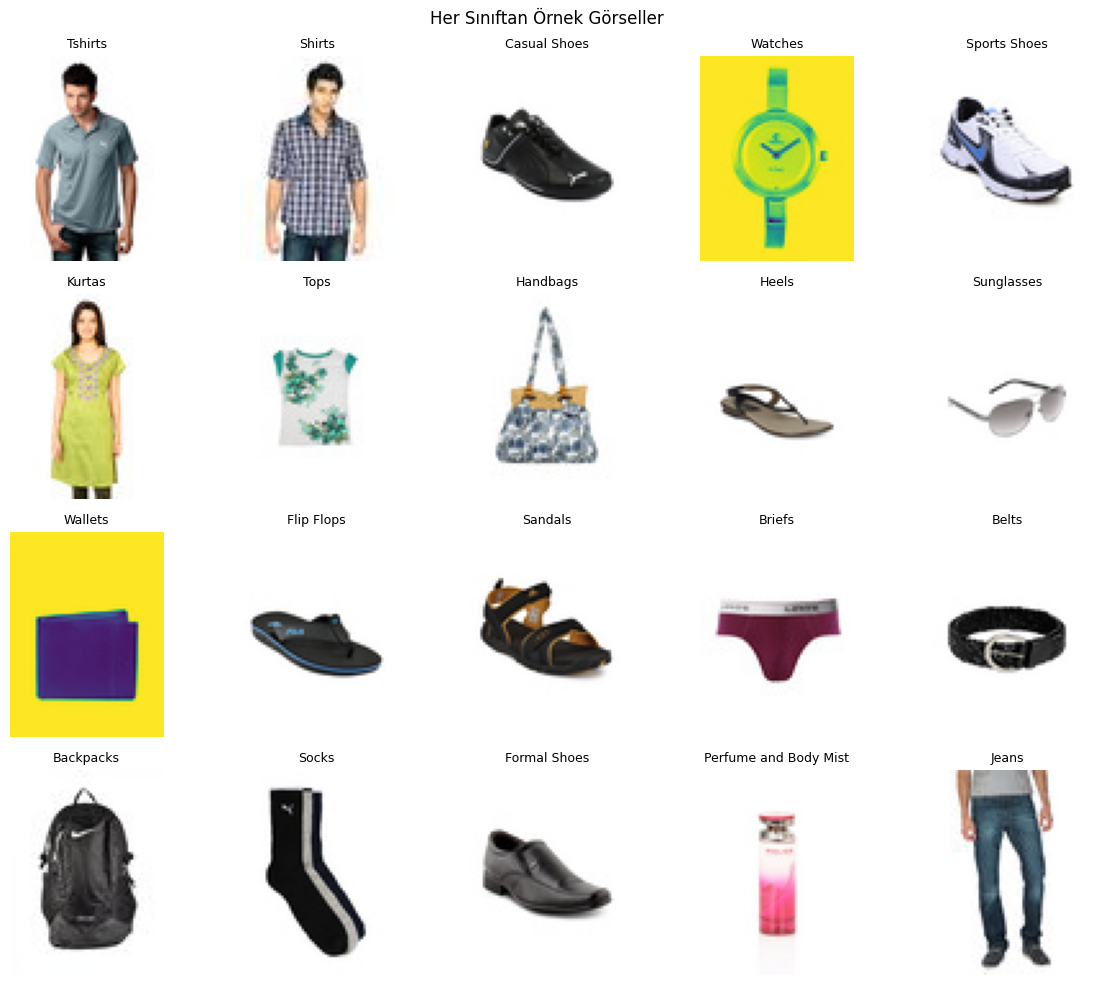

In [92]:
from PIL import Image

siniflar = sinif_sayilari.index          # 20 sınıfın adı, büyükten küçüğe

fig, eksenler = plt.subplots(4, 5, figsize=(12, 10))

for eksen, sinif in zip(eksenler.flat, siniflar):
    # bu sınıfa ait ilk ürünün idsini aldım
    ornek_id = df[df["articleType"] == sinif]["id"].iloc[0]

    gorsel = Image.open(f"{veri_yolu}/images/{ornek_id}.jpg")


    eksen.imshow(gorsel)
    eksen.set_title(sinif, fontsize=9)
    eksen.axis("off")

plt.suptitle("Her Sınıftan Örnek Görseller")
plt.tight_layout()
plt.savefig(f"{CIKTI}/ornek_gorseller.png", dpi=150)
plt.show()


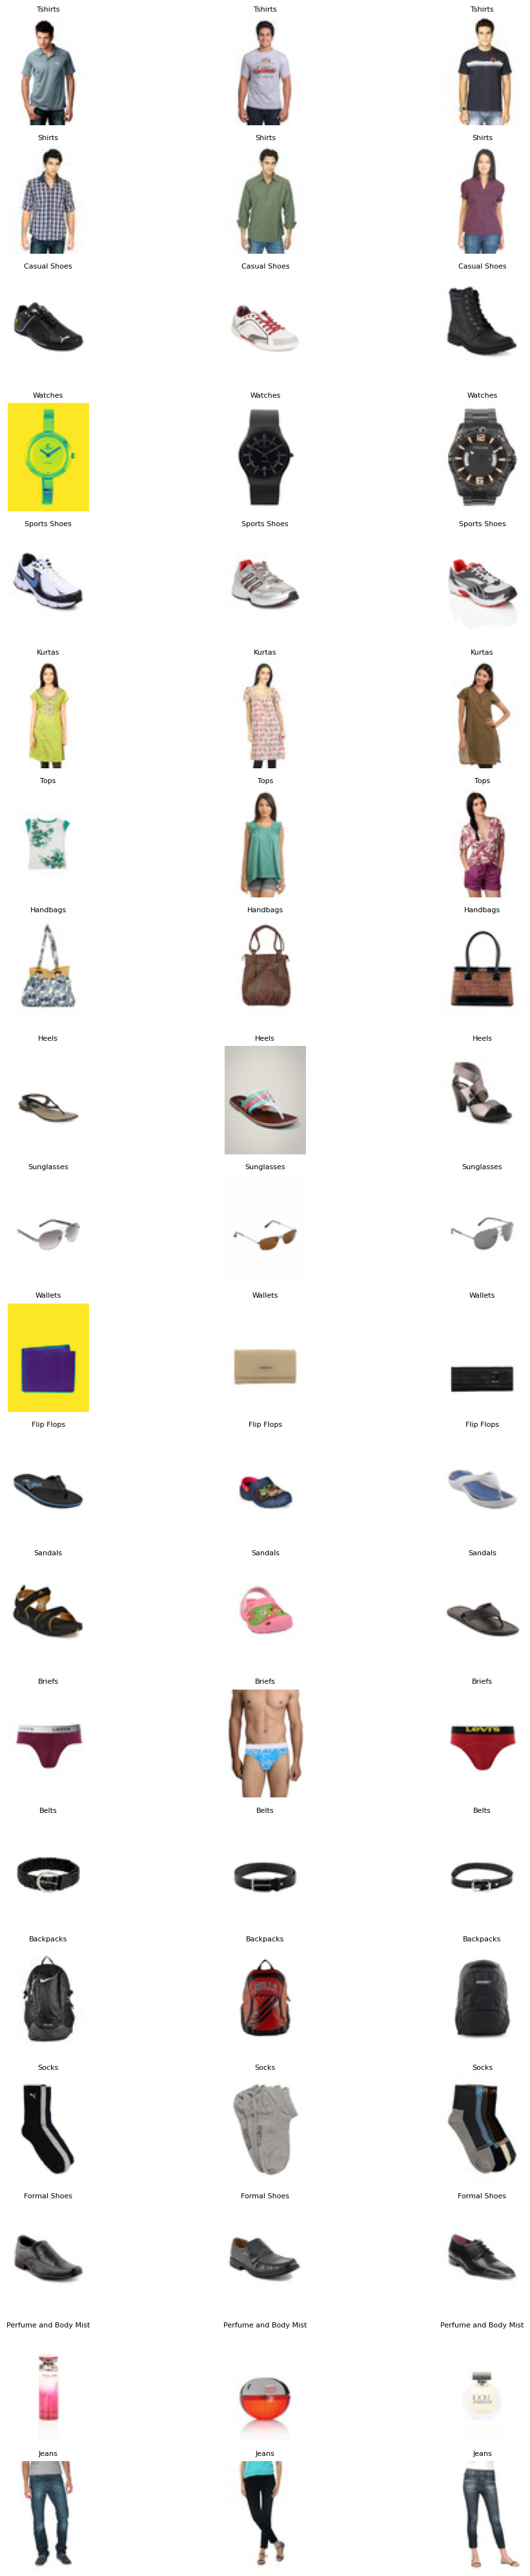

In [93]:
#her Sınıftan 3 Örnek Görsel
fig, eksenler = plt.subplots(20, 3, figsize=(12, 40))

for satir_no, sinif in enumerate(siniflar):
    # bu sınıftaki bütün ürünlerin id'leri
    sinif_idleri = df[df["articleType"] == sinif]["id"]

    for sutun_no in range(3):
        ornek_id = sinif_idleri.iloc[sutun_no]
        gorsel = Image.open(f"{veri_yolu}/images/{ornek_id}.jpg")

        eksen = eksenler[satir_no, sutun_no]
        eksen.imshow(gorsel)
        eksen.set_title(sinif, fontsize=8)
        eksen.axis("off")

plt.tight_layout()
plt.savefig(f"{CIKTI}/ornek_gorseller_3lu.png", dpi=150)
plt.show()


Yaptığım analiz: Görseller 60×80 piksel. Flip Flops ve Sandals sınıflarının görselleri birbirine çok benziyor. Heels , casual shoes gibi bazı ürünlerde isim ve görsel uyumsuzluğu var.


### 4.3 Ürün adı uzunluğu

In [94]:
df["kelime_sayisi"] = df["productDisplayName"].str.split().str.len()


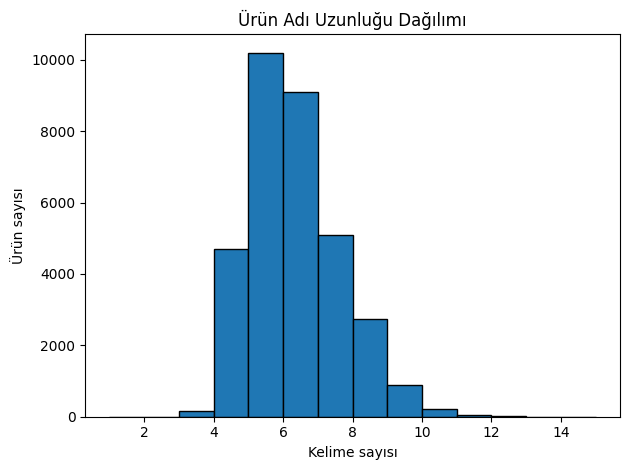

In [95]:
df["kelime_sayisi"].plot(kind="hist", bins=range(1, 16), edgecolor="black")

plt.title("Ürün Adı Uzunluğu Dağılımı")
plt.xlabel("Kelime sayısı")
plt.ylabel("Ürün sayısı")
plt.tight_layout()
plt.savefig(f"{CIKTI}/ad_uzunlugu.png", dpi=150)
plt.show()


In [96]:
df["kelime_sayisi"].describe()


,kelime_sayisi
count,33142.000000
mean,5.833353
std,1.339354
min,1.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,14.000000


### 4.4 Tek kelimelik ürün adları

İlk incelemede tek kelimelik 3 ad vardı. Playboy, RTV_LoadTest, productDisplayName.
Son ikisi gerçek ürün adı olmadığı için 3.2'deki gecersiz_adlar listesine eklendi ve çıkarıldı.
Playboy gerçek bir marka adı olduğu için tutuldu.


In [97]:
!grep -n "RTV_LoadTest\|productDisplayName" {veri_yolu}/styles.csv # verinin ham halinde geçersiz isimleri gösterdim


1:id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
8545:28319,Men,Footwear,Sandal,Sandals,Brown,Winter,2018,,RTV_LoadTest
21859:24078,Women,Footwear,Shoes,Heels,Black,Winter,2015,Casual,productDisplayName


In [98]:
df.loc[df["kelime_sayisi"].idxmin()]

,8730
id,47238
productDisplayName,Playboy
articleType,Casual Shoes
kelime_sayisi,1


In [99]:
df[df["kelime_sayisi"] == 1]

,id,productDisplayName,articleType,kelime_sayisi
8730,47238,Playboy,Casual Shoes,1


inceleme: id 28319 ("RTV_LoadTest") görseli spor ayakkabı ancak Sandals etiketli.bu kayıt geçersiz adlar listesine eklenerek veri setinden çıkarılmıştı.

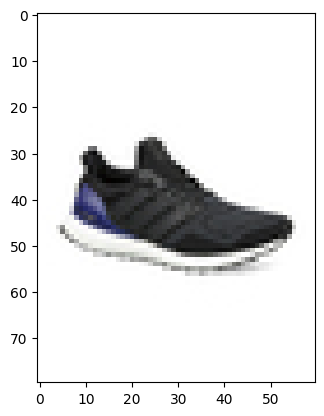

In [100]:

plt.imshow(Image.open(f"{veri_yolu}/images/28319.jpg"))
plt.show()


## 5. Veri bölme (%70 / %15 / %15, tabakalı, sabit tohum)

In [101]:
from sklearn.model_selection import train_test_split

# 1. bölme: %70 train, %30 geri kalan
train_df, gecici_df = train_test_split(df, test_size=0.30, stratify=df["articleType"], random_state=42)

# 2. bölme: geri kalanın yarısı val, yarısı test
val_df, test_df = train_test_split(gecici_df, test_size=0.50, stratify=gecici_df["articleType"], random_state=42)

print(len(train_df), len(val_df), len(test_df))


23199 4971 4972


In [102]:
oranlar = pd.DataFrame({
    "train": train_df["articleType"].value_counts(normalize=True),
    "val":   val_df["articleType"].value_counts(normalize=True),
    "test":  test_df["articleType"].value_counts(normalize=True),
})
print(oranlar.round(3))


                       train    val   test
articleType                               
Backpacks              0.022  0.022  0.022
Belts                  0.025  0.025  0.025
Briefs                 0.026  0.026  0.026
Casual Shoes           0.086  0.086  0.086
Flip Flops             0.028  0.028  0.028
Formal Shoes           0.019  0.019  0.019
Handbags               0.053  0.053  0.053
Heels                  0.040  0.040  0.040
Jeans                  0.018  0.018  0.018
Kurtas                 0.056  0.056  0.056
Perfume and Body Mist  0.018  0.019  0.018
Sandals                0.027  0.027  0.027
Shirts                 0.097  0.097  0.097
Socks                  0.021  0.021  0.021
Sports Shoes           0.061  0.061  0.062
Sunglasses             0.032  0.032  0.032
Tops                   0.053  0.053  0.053
Tshirts                0.213  0.213  0.213
Wallets                0.028  0.028  0.028
Watches                0.077  0.077  0.077


split.csv yalnızca bölmeyi tutuyor. hangi ürünün hangi kümede olduğunu bilmek için id ve küme yeterli. Diğer bilgileri id ile eşleştirip alıyorum.

In [103]:
split = pd.concat([
    train_df.assign(kume="train"),
    val_df.assign(kume="val"),
    test_df.assign(kume="test"),
])

split = split[["id", "kume"]]
split.to_csv(f"{CIKTI}/split.csv", index=False)

print(split["kume"].value_counts())
print(split.head(10))


kume
train    23199
test      4972
val       4971
Name: count, dtype: int64
          id   kume
12458  44764  train
15733  19137  train
14280  53125  train
21427  49371  train
29958  49828  train
723    54116  train
7963   46564  train
32529   6662  train
28266   2916  train
4573   20382  train


### Aynı ürün adının birden fazla kümede olması

In [104]:
train_adlari = set(train_df["productDisplayName"])
test_adlari  = set(test_df["productDisplayName"])

ortak = train_adlari & test_adlari

print("Testteki farklı ad sayısı:", len(test_adlari))
print("Bunlardan train'de de olan:", len(ortak))
print("Oran:", round(len(ortak) / len(test_adlari) * 100, 1), "%")


Testteki farklı ad sayısı: 4394
Bunlardan train'de de olan: 1400
Oran: 31.9 %


In [105]:
test_df["productDisplayName"].isin(train_adlari).mean()


np.float64(0.38555913113435236)

Test adlarının %31,9'u (kayıtların %38,6'sı) train'de de geçiyor. Bölme korunuyor; bu durumun etkisi bölüm 8'de görülmüş/görülmemiş adlar için ayrı ölçülüyor.

## 6. Metin modeli

### 6.1 TF-IDF

Modeli kurmadan önce TF-IDF'in ürün adlarını nasıl sayılara çevirdiğini üç kısa
adla denedim. Bir
kelime az sayıda adda geçiyorsa daha yüksek ağırlık aldı (yalnızca bir adda
geçen "nike" 0,60), birçok adda geçiyorsa daha düşük ağırlık aldı ( "men" 0,43–0,46)

In [106]:
from sklearn.feature_extraction.text import TfidfVectorizer

ornek = ["Puma Men Grey T-shirt", "Nike Men Black Shoes", "Puma Women Black Shoes"]
v = TfidfVectorizer()
X = v.fit_transform(ornek)

print(v.get_feature_names_out()) #her sütun bir kelimeyi her satır bir ürün adını gösteriyor.
print(X.toarray().round(2))


['black' 'grey' 'men' 'nike' 'puma' 'shirt' 'shoes' 'women']
[[0.   0.56 0.43 0.   0.43 0.56 0.   0.  ]
 [0.46 0.   0.46 0.6  0.   0.   0.46 0.  ]
 [0.46 0.   0.   0.   0.46 0.   0.46 0.6 ]]


Üç kümedeki ürün adlarını TF-IDF ile sayılara *çevirdim*

In [107]:
tfidf = TfidfVectorizer()

X_train = tfidf.fit_transform(train_df["productDisplayName"])   # öğren + çevir
X_val   = tfidf.transform(val_df["productDisplayName"])         # sadece çevir
X_test  = tfidf.transform(test_df["productDisplayName"])        # sadece çevir

print("Kelime sayısı (sözlük):", len(tfidf.get_feature_names_out()))
print("X_train boyutu:", X_train.shape)
print("X_val boyutu:  ", X_val.shape)
print("X_test boyutu: ", X_test.shape)


Kelime sayısı (sözlük): 5821
X_train boyutu: (23199, 5821)
X_val boyutu:   (4971, 5821)
X_test boyutu:  (4972, 5821)


### 6.2 Lojistik regresyon ve doğrusal SVM

In [108]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

y_train = train_df["articleType"]
y_val   = val_df["articleType"]

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)          # train ile öğren

val_tahmin = lr.predict(X_val)    # val için tahmin et

print("Doğruluk:", round(accuracy_score(y_val, val_tahmin), 4))
print("Makro-F1:", round(f1_score(y_val, val_tahmin, average="macro"), 4))



Doğruluk: 0.9646
Makro-F1: 0.9761


In [109]:
from sklearn.metrics import classification_report

print(classification_report(y_val, val_tahmin, digits=3))


                       precision    recall  f1-score   support

            Backpacks      1.000     0.963     0.981       109
                Belts      1.000     1.000     1.000       122
               Briefs      1.000     0.969     0.984       128
         Casual Shoes      0.947     0.956     0.951       427
           Flip Flops      0.978     0.964     0.971       137
         Formal Shoes      0.967     0.906     0.935        96
             Handbags      0.985     0.989     0.987       264
                Heels      0.975     0.990     0.982       198
                Jeans      1.000     1.000     1.000        91
               Kurtas      1.000     0.996     0.998       276
Perfume and Body Mist      1.000     0.989     0.995        92
              Sandals      0.985     0.963     0.974       135
               Shirts      0.933     0.863     0.897       482
                Socks      1.000     1.000     1.000       103
         Sports Shoes      0.951     0.948     0.949  

In [110]:
from sklearn.svm import LinearSVC

svm = LinearSVC()
svm.fit(X_train, y_train)                 # train ile öğren

svm_val_tahmin = svm.predict(X_val)       # val için tahmin et

print("Doğruluk:", round(accuracy_score(y_val, svm_val_tahmin), 4))
print("Makro-F1:", round(f1_score(y_val, svm_val_tahmin, average="macro"), 4))
print(classification_report(y_val, svm_val_tahmin, digits=3))


Doğruluk: 0.969
Makro-F1: 0.9791
                       precision    recall  f1-score   support

            Backpacks      1.000     0.963     0.981       109
                Belts      1.000     1.000     1.000       122
               Briefs      1.000     1.000     1.000       128
         Casual Shoes      0.956     0.960     0.958       427
           Flip Flops      0.978     0.964     0.971       137
         Formal Shoes      0.967     0.917     0.941        96
             Handbags      0.985     0.996     0.991       264
                Heels      0.985     0.990     0.987       198
                Jeans      1.000     1.000     1.000        91
               Kurtas      1.000     0.996     0.998       276
Perfume and Body Mist      1.000     1.000     1.000        92
              Sandals      0.970     0.963     0.967       135
               Shirts      0.924     0.888     0.906       482
                Socks      1.000     1.000     1.000       103
         Sports Shoes

### 6.3 Hiperparametre seçimi
En sık hata Shirts → Tshirts. Varsayılan TF-IDF "T-shirt" içindeki tek harfli "t"yi attığı için iki sınıf aynı
"shirt" kelimesine dönüşüyordu. Tek harfleri koruyan bir ayarla denedim ardından bütün seçenekleri karşılaştırdım.

In [111]:
tfidf_b = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b") # tek harfli parçaları da kelime olarak tutan deneme
X_train_b = tfidf_b.fit_transform(train_df["productDisplayName"])
X_val_b   = tfidf_b.transform(val_df["productDisplayName"])
# t harfini de artık kelime olarak sydırdıktan sonra tekrar değişime baktım
svm_b = LinearSVC()
svm_b.fit(X_train_b, y_train)
tahmin_b = svm_b.predict(X_val_b)

print("Makro-F1:", round(f1_score(y_val, tahmin_b, average="macro"), 4))
print(classification_report(y_val, tahmin_b, digits=3))


Makro-F1: 0.9862
                       precision    recall  f1-score   support

            Backpacks      1.000     0.972     0.986       109
                Belts      1.000     1.000     1.000       122
               Briefs      1.000     1.000     1.000       128
         Casual Shoes      0.952     0.965     0.958       427
           Flip Flops      0.978     0.964     0.971       137
         Formal Shoes      0.967     0.917     0.941        96
             Handbags      0.989     0.996     0.992       264
                Heels      0.985     0.990     0.987       198
                Jeans      1.000     1.000     1.000        91
               Kurtas      1.000     0.996     0.998       276
Perfume and Body Mist      1.000     1.000     1.000        92
              Sandals      0.970     0.963     0.967       135
               Shirts      1.000     0.992     0.996       482
                Socks      1.000     1.000     1.000       103
         Sports Shoes      0.954     

In [112]:
print("t" in tfidf_b.get_feature_names_out()) # t harfi gerçekten sözlüğe girmiş mi ?


True


In [113]:
# denenecek TF-IDF ayarları
tfidf_secenekleri = {
    "a_varsayilan":  {},
    "b_tek_harf":    {"token_pattern": r"(?u)\b\w+\b"},
    "c_karakter":    {"analyzer": "char_wb", "ngram_range": (2, 5)}, # kelimeyi 2-5 karakter aralığına böldüm
}

# denenecek modeller ve c değerleri
C_degerleri = [0.1, 1, 10] # 10'ar katlı değerlerle genel aralığı bulmak için

sonuclar = []

for tfidf_adi, ayarlar in tfidf_secenekleri.items():

    vektorlestirici = TfidfVectorizer(**ayarlar)
    Xtr = vektorlestirici.fit_transform(train_df["productDisplayName"])
    Xva = vektorlestirici.transform(val_df["productDisplayName"])

    for C in C_degerleri:
        for model_adi, model in [
            ("LR",  LogisticRegression(C=C, max_iter=2000)),
            ("SVM", LinearSVC(C=C)),
        ]:
            model.fit(Xtr, y_train)
            tahmin = model.predict(Xva)
            sonuclar.append({
                "tfidf": tfidf_adi,
                "model": model_adi,
                "C": C,
                "makro_f1": round(f1_score(y_val, tahmin, average="macro"), 4),
                "dogruluk": round(accuracy_score(y_val, tahmin), 4),
            })

sonuc_tablosu = pd.DataFrame(sonuclar).sort_values("makro_f1", ascending=False)
print(sonuc_tablosu.to_string(index=False))


       tfidf model    C  makro_f1  dogruluk
  c_karakter    LR 10.0    0.9875    0.9875
  b_tek_harf    LR 10.0    0.9867    0.9867
  c_karakter   SVM  1.0    0.9864    0.9873
  b_tek_harf   SVM  1.0    0.9862    0.9867
  c_karakter    LR  1.0    0.9848    0.9849
  c_karakter   SVM 10.0    0.9847    0.9849
  b_tek_harf   SVM 10.0    0.9845    0.9841
  b_tek_harf    LR  1.0    0.9841    0.9841
  c_karakter   SVM  0.1    0.9838    0.9841
  b_tek_harf   SVM  0.1    0.9828    0.9829
a_varsayilan    LR 10.0    0.9797    0.9696
a_varsayilan   SVM  1.0    0.9791    0.9690
a_varsayilan   SVM 10.0    0.9775    0.9672
a_varsayilan    LR  1.0    0.9761    0.9646
a_varsayilan   SVM  0.1    0.9746    0.9628
  c_karakter    LR  0.1    0.9714    0.9728
  b_tek_harf    LR  0.1    0.9628    0.9638
a_varsayilan    LR  0.1    0.9517    0.9390


En iyi ayar: karakter TF-IDF(2-5)  + lojistik regresyon, C = 10.

In [114]:
tfidf_en_iyi = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
X_train_c = tfidf_en_iyi.fit_transform(train_df["productDisplayName"])
X_val_c   = tfidf_en_iyi.transform(val_df["productDisplayName"])

lr_en_iyi = LogisticRegression(C=10, max_iter=2000)
lr_en_iyi.fit(X_train_c, y_train)
tahmin_en_iyi = lr_en_iyi.predict(X_val_c)

print("Makro-F1:", round(f1_score(y_val, tahmin_en_iyi, average="macro"), 4))
print(classification_report(y_val, tahmin_en_iyi, digits=3))


Makro-F1: 0.9875
                       precision    recall  f1-score   support

            Backpacks      1.000     0.991     0.995       109
                Belts      1.000     1.000     1.000       122
               Briefs      1.000     0.992     0.996       128
         Casual Shoes      0.958     0.965     0.961       427
           Flip Flops      0.985     0.971     0.978       137
         Formal Shoes      0.967     0.927     0.947        96
             Handbags      0.989     0.996     0.992       264
                Heels      0.985     0.990     0.987       198
                Jeans      1.000     1.000     1.000        91
               Kurtas      1.000     0.996     0.998       276
Perfume and Body Mist      1.000     1.000     1.000        92
              Sandals      0.978     0.970     0.974       135
               Shirts      1.000     0.990     0.995       482
                Socks      1.000     1.000     1.000       103
         Sports Shoes      0.955     

In [115]:
# en düşük F1 değerleri ayakkabı sınıflarında. yanlış tahmin edilen ayakkabılar:
yanlis = val_df[tahmin_en_iyi != y_val].copy()

yanlis["tahmin"] = tahmin_en_iyi[tahmin_en_iyi != y_val]
ayakkabi = yanlis[yanlis["articleType"].str.contains("Shoes")]
print(ayakkabi[["productDisplayName", "articleType", "tahmin"]].to_string())


                                    productDisplayName   articleType        tahmin
9105                          Red Tape Men Brown Shoes  Formal Shoes  Casual Shoes
12899             Nike Women Dunk Low Light Brown Shoe  Casual Shoes  Sports Shoes
22657                               Btwin Road Shoes 5  Sports Shoes  Casual Shoes
23545            ADIDAS Men's Orbid NYC Dark Blue Shoe  Casual Shoes  Sports Shoes
7236             Lotto Men's Fuerzapura Red Black Shoe  Sports Shoes  Casual Shoes
31546                          Ganuchi Men Brown Shoes  Formal Shoes  Casual Shoes
8543                        Numero Uno Men Brown Shoes  Formal Shoes  Casual Shoes
8323              ADIDAS Women Boat Black Icegrey Shoe  Casual Shoes  Sports Shoes
12310  Rockport Men's Hydro Sail Navy Blue Yellow Shoe  Sports Shoes  Casual Shoes
5642                Nike Men Sports White Casual Shoes  Casual Shoes  Sports Shoes
2424                      GAS Men Grey Skate 002 Shoes  Sports Shoes  Casual Shoes
2533

## 7. Maskeleme deneyi
Sınıf adlarını oluşturan kelimeler (tekil ve çoğul biçimleriyle) ürün adlarından silinip aynı model yeniden eğitiliyor.
Önce bazı sınıflarda ürün adlarının nasıl yazıldığına bakıldı eğer bakmadan yapsaydım eksik kalan isimler lurdu ve bazı ürün adları maskelenmeden kalırdı.

In [116]:
df[df["articleType"] == "Tshirts"]["productDisplayName"].sample(15, random_state=1)


,productDisplayName
23041,Angry Birds Women White T-shirt
18822,ADIDAS Women's Flora White T-shirt
7580,Nike Women Pink Polo T-shirt
22370,ADIDAS Men Black T-shirt
4637,Myntra Men's Yoga White T-shirt
30673,Elle Women Dark Pink T-shirt
15376,ADIDAS Men Navy Blue T-shirt
30250,United Colors of Benetton Men Printed Tan T-shirt
12300,Puma Men's Heroes T-shirt
6215,Madagascar3 Boys Blue Printed T-Shirt


In [117]:
df[df["articleType"] == "Watches"]["productDisplayName"].sample(15, random_state=1)


,productDisplayName
18966,Q&Q Men Steel Dial Watch
23605,Fastrack Women Pink Dial Watch
27056,Timex Men Gunmetal Toned Dial Watch
22976,Guess Women White Dial Watch I90192L1
18093,CASIO Women Black & Steel Analogue Watch
9519,Fastrack Women White Dial Watch
3354,Casio Enticer Men Silver-Toned Dial Chronograp...
16262,Q&Q Attractive Men Silver Dial Watch
22302,Citizen Men White Dial Watch
13811,Titan Men Black Watch


In [118]:
df[df["articleType"] == "Heels"]["productDisplayName"].sample(15, random_state=1)

,productDisplayName
7349,Catwalk Women Lifestyle Pink Flats
4584,Catwalk Women Casual Silver Heels
21719,Catwalk Women Black Heels
27064,Catwalk Women Brown Wedges
4487,Catwalk Women Black Heels
6739,Tiptopp Women Black Sandals
31543,Enroute Women Casual Gold Flats
32375,Senorita Women Orange Flats
32198,Rockport Women Casual Black Flats
15366,Senorita Women Multi Coloured Flats


In [119]:
df[df["articleType"] == "Jeans"]["productDisplayName"].sample(15, random_state=1)

,productDisplayName
3459,Jealous 21 Women Blue Jeans
13177,Spykar Men Washed Navy Blue Jeans
8315,Pepe Jeans Women Blue Jeans
25366,Gini and Jony Boys Rodeo Blue Jeans
10573,Scullers For Her Women Blue Jeans
13116,Spykar Men Washed Blue Jeans
17507,Lee Women Navy Blue Jeggings
26398,Spykar Women Blue Jeans
13324,Deni Yo Men Washed Blue Jeans
4612,Wrangler Men Blue Texas Jeans


In [120]:
import re

# sınıf adlarındaki kelimeler (tekil + çoğul + veride görülen yazımlar)
# tireli biçimler (t-shirt, flip-flop) daha kısa kelimelerden ÖNCE yazılmalı
maske_kelimeleri = [
    "t-shirts", "t-shirt", "tshirts", "tshirt",                # Tshirts
    "flip-flops", "flip-flop",                       # Flip Flops (tireli yazım)
    "shirts", "shirt",                               # Shirts
    "casual", "shoes", "shoe",                       # Casual Shoes
    "watches", "watch",                              # Watches
    "sports", "sport",                               # Sports Shoes
    "kurtas", "kurta",                               # Kurtas
    "tops", "top",                                   # Tops
    "handbags", "handbag",                           # Handbags
    "heels", "heel",                                 # Heels
    "sunglasses", "sunglass",                        # Sunglasses
    "wallets", "wallet",                             # Wallets
    "flips", "flip", "flops", "flop",                # Flip Flops
    "sandals", "sandal",                             # Sandals
    "briefs", "brief",                               # Briefs
    "belts", "belt",                                 # Belts
    "backpacks", "backpack",                         # Backpacks
    "socks", "sock",                                 # Socks
    "formal",                                        # Formal Shoes
    "perfumes", "perfume", "body", "mists", "mist",  # Perfume and Body Mist
    "jeans", "jean",                                 # Jeans
]

# listedeki kelimelerden herhangi birini tam eşleşme olarak bulan desen
desen = re.compile(r"\b(" + "|".join(re.escape(k) for k in maske_kelimeleri) + r")\b",
                   re.IGNORECASE)

def maskele(ad):
    ad = desen.sub(" ", ad)            # eşleşen kelimeleri sil
    ad = re.sub(r"\s+", " ", ad)       # birden fazla boşluğu teke indir
    return ad.strip()                  # baştaki/sondaki boşlukları sil

# kontrol için

for ornek in ["Turtle Check Men Navy Blue Shirt",
              "Puma Men Grey T-shirt",
              "Nike Men Sports White Casual Shoes",
              "Converse Unisex Navy Blue Liv,Laugh,Love Flip-flops",
              "Titan Women Silver Watch"]:
    print(ornek, "→", maskele(ornek))


Turtle Check Men Navy Blue Shirt → Turtle Check Men Navy Blue
Puma Men Grey T-shirt → Puma Men Grey
Nike Men Sports White Casual Shoes → Nike Men White
Converse Unisex Navy Blue Liv,Laugh,Love Flip-flops → Converse Unisex Navy Blue Liv,Laugh,Love
Titan Women Silver Watch → Titan Women Silver


In [121]:
# üç kümenin adlarını maskeledim
train_df = train_df.assign(ad_maskeli=train_df["productDisplayName"].apply(maskele))
val_df   = val_df.assign(ad_maskeli=val_df["productDisplayName"].apply(maskele))
test_df  = test_df.assign(ad_maskeli=test_df["productDisplayName"].apply(maskele))

print("Maskeleme sonrası boş kalan ad:", (train_df["ad_maskeli"] == "").sum())

# en iyi metin modeliyle denedim
tfidf_maske = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
X_train_m = tfidf_maske.fit_transform(train_df["ad_maskeli"])
X_val_m   = tfidf_maske.transform(val_df["ad_maskeli"])

lr_maske = LogisticRegression(C=10, max_iter=2000)
lr_maske.fit(X_train_m, y_train)
tahmin_maske = lr_maske.predict(X_val_m)

print("Maskeli  → Doğruluk:", round(accuracy_score(y_val, tahmin_maske), 4),
      "| Makro-F1:", round(f1_score(y_val, tahmin_maske, average="macro"), 4))
print("Orijinal → Doğruluk:", round(accuracy_score(y_val, tahmin_en_iyi), 4),
      "| Makro-F1:", round(f1_score(y_val, tahmin_en_iyi, average="macro"), 4))
print(classification_report(y_val, tahmin_maske, digits=3))


Maskeleme sonrası boş kalan ad: 0
Maskeli  → Doğruluk: 0.8431 | Makro-F1: 0.8206
Orijinal → Doğruluk: 0.9875 | Makro-F1: 0.9875
                       precision    recall  f1-score   support

            Backpacks      0.865     0.826     0.845       109
                Belts      0.677     0.549     0.606       122
               Briefs      0.984     0.977     0.980       128
         Casual Shoes      0.703     0.731     0.716       427
           Flip Flops      0.835     0.664     0.740       137
         Formal Shoes      0.593     0.729     0.654        96
             Handbags      0.853     0.837     0.845       264
                Heels      0.941     0.975     0.958       198
                Jeans      0.888     0.868     0.878        91
               Kurtas      0.961     0.989     0.975       276
Perfume and Body Mist      0.957     0.957     0.957        92
              Sandals      0.720     0.496     0.588       135
               Shirts      0.880     0.834     0.856

In [122]:
yanlis_m = val_df[tahmin_maske != y_val].copy()
yanlis_m["tahmin"] = tahmin_maske[tahmin_maske != y_val]
print(yanlis_m[yanlis_m["articleType"] == "Belts"][["ad_maskeli", "tahmin"]].head(10).to_string())


                                    ad_maskeli        tahmin
2929             Lino Perros Men Black Leather       Wallets
15710             Lino Perros Women Solid Blue      Handbags
24156          Belmonte Men Rough Finish Black       Wallets
31269              Baggit Women Brown Sunshine      Handbags
10967  Wrangler Men Classic Double Stich Brown        Shirts
6066                   Fossil Men Brown Justin       Wallets
15374                  Lino Perros Women Black      Handbags
10574             Fastrack Men Black and Olive       Watches
19591                  Lino Perros Women Green      Handbags
10252                   Puma Men Bolt LS Black  Sports Shoes


## 8. Test sonuçları (Tablo 1, satır 1–3)
Ayarlar doğrulama kümesinde seçildi ve test kümesini artk kullandım

In [123]:
from sklearn.svm import LinearSVC

y_test = test_df["articleType"]

def egit_ve_test_et(sutun, model):
    """TF-IDF'i train ile öğrenir, modeli eğitir, test kümesinde tahmin yapar."""
    vek = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))
    Xtr = vek.fit_transform(train_df[sutun])
    Xte = vek.transform(test_df[sutun])
    model.fit(Xtr, y_train)
    return model.predict(Xte)

# val kümesinde seçilen ayarlar
test_tahminleri = {
    "1. TF-IDF + LR (orijinal)":    egit_ve_test_et("productDisplayName", LogisticRegression(C=10, max_iter=2000)),
    "2. TF-IDF + SVM (orijinal)":   egit_ve_test_et("productDisplayName", LinearSVC(C=1)),
    "3. En iyi model (maskelenmiş)": egit_ve_test_et("ad_maskeli",        LogisticRegression(C=10, max_iter=2000)),
}

# train'de görülmüş / görülmemiş test kayıtları
gorulmus = test_df["productDisplayName"].isin(set(train_df["productDisplayName"])).values
print("Görülmüş:", gorulmus.sum(), "| Görülmemiş:", (~gorulmus).sum())

satirlar = []
for ad, tahmin in test_tahminleri.items():
    satirlar.append({
        "Model": ad,
        "Doğruluk": round(accuracy_score(y_test, tahmin), 4),
        "Makro-F1": round(f1_score(y_test, tahmin, average="macro"), 4),
        "Makro-F1 (görülmüş ad)":   round(f1_score(y_test[gorulmus],  tahmin[gorulmus],  average="macro"), 4),
        "Makro-F1 (görülmemiş ad)": round(f1_score(y_test[~gorulmus], tahmin[~gorulmus], average="macro"), 4),
    })

tablo1_metin = pd.DataFrame(satirlar)
print(tablo1_metin.to_string(index=False))
tablo1_metin.to_csv(f"{CIKTI}/tablo1_metin.csv", index=False)


Görülmüş: 1917 | Görülmemiş: 3055
                        Model  Doğruluk  Makro-F1  Makro-F1 (görülmüş ad)  Makro-F1 (görülmemiş ad)
    1. TF-IDF + LR (orijinal)    0.9843    0.9821                  0.9944                    0.9750
   2. TF-IDF + SVM (orijinal)    0.9849    0.9835                  0.9956                    0.9769
3. En iyi model (maskelenmiş)    0.8407    0.8172                  0.8519                    0.7810


## 9. Diğer not defterleri için veri kaydı

In [124]:
# diğer notebooklarda kullanmak için hazırlanmış veriyi kaydettim
hazir_veri = pd.concat([
    train_df.assign(kume="train"),
    val_df.assign(kume="val"),
    test_df.assign(kume="test"),
])[["id", "productDisplayName", "ad_maskeli", "articleType", "kume"]]

hazir_veri.to_csv(f"{CIKTI}/hazir_veri.csv", index=False)
print(hazir_veri.shape)
print(hazir_veri["kume"].value_counts())


(33142, 5)
kume
train    23199
test      4972
val       4971
Name: count, dtype: int64
